# Universe overview · observed holdings only

**Goal:** build one option book for every fund in `data/sheets/` that has listed holdings, then answer:
*how much dollar gamma and vega does this complex put on the street, and how does it change when the market moves?*

Pipeline (`core/pipeline.py`):
1. Fund has legs in `Option_Book_Copy` + `holdings/` → **observed** (priced)
2. Otherwise → **skipped** (prospectus inference later; not in this notebook)

Then: dollar Greeks by fund / bucket / expiry, spot ladders, gamma-flip, hedge-flow story.


In [18]:
import sys
from pathlib import Path

HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "examples" else HERE
if not (ROOT / "data" / "sheets" / "ETF_List.csv").exists():
    cand = Path("..").resolve()
    if (cand / "data" / "sheets" / "ETF_List.csv").exists():
        ROOT = cand

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "examples"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from core import pipeline, greek_engine
import _plot_style as ps

ps.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}" if abs(x) < 10 else f"{x:,.0f}")
pd.set_option("display.width", 160)
print("ROOT =", ROOT)


ROOT = /Users/orangeao/OrangeAo/StudyMaterials/Columbia/CBS/Derivatives.M.Zurack/Assignments/OptionEmbededEFTs


## 1 · Coverage: observed vs skipped (no holdings yet)


In [19]:
book, coverage, etfs, mkt = pipeline.build_from_sheets(ROOT / "data" / "sheets")
coverage[["fund", "bucket", "aum_usd", "status", "n_legs", "note"]].sort_values(
    "aum_usd", ascending=False
)


,fund,bucket,aum_usd,status,n_legs,note
0,JEPI US Equity,ELN income,"45,168,984,000",excluded,0,ELN overlay — awaiting prospectus (placeholder...
1,JEPQ US Equity,ELN income,"40,419,164,000",excluded,0,ELN overlay — awaiting prospectus (placeholder...
2,BOXX US Equity,Box spread,"14,601,127,000",observed,8,
3,QQQI US Equity,Index option income,"14,467,057,000",observed,2,
4,SPYI US Equity,Index option income,"12,195,136,000",observed,2,
5,BUFR US Equity,Buffer fund of funds,"10,729,497,000",excluded,0,buffer fund-of-funds — awaiting prospectus / l...
6,QYLD US Equity,Index covered call,"7,740,906,000",observed,2,
7,DIVO US Equity,Tactical single-stock covered call,"7,606,742,000",observed,7,
8,GPIX US Equity,Active option income,"6,386,987,000",observed,4,
9,GPIQ US Equity,Active option income,"6,215,317,000",observed,4,


Funds without holdings (`status == skipped`) are left out of the priced book.
We will add prospectus-based inference for those later.


In [20]:
n_obs = int((coverage["status"] == "observed").sum())
n_skip = int((coverage["status"] == "skipped").sum())
print(f"# with observed holdings (priced): {n_obs}")
print(f"# skipped (infer later):         {n_skip}")
print(f"# option legs in book:           {len(book)}")


# with observed holdings (priced): 15
# skipped (infer later):         0
# option legs in book:           285


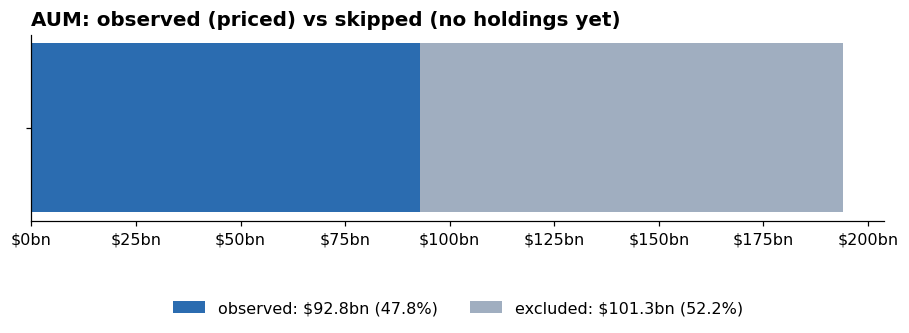

In [21]:
cov = coverage.groupby("status")["aum_usd"].sum().sort_values()
fig, ax = plt.subplots(figsize=(10, 2.2))
left = 0
for status, value in cov.items():
    ax.barh(
        [""], [value], left=left,
        color=ps.COLORS.get(status, "grey"),
        label=f"{status}: {ps.money(value)} ({value / cov.sum():.1%})",
    )
    left += value
ps.usd(ax, "x", 1e9, "bn")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.35))
ax.grid(False)
ax.set_title("AUM: observed (priced) vs skipped (no holdings yet)")
plt.show()


## 2 · Dollar Greeks by fund (from market-maker's POV)

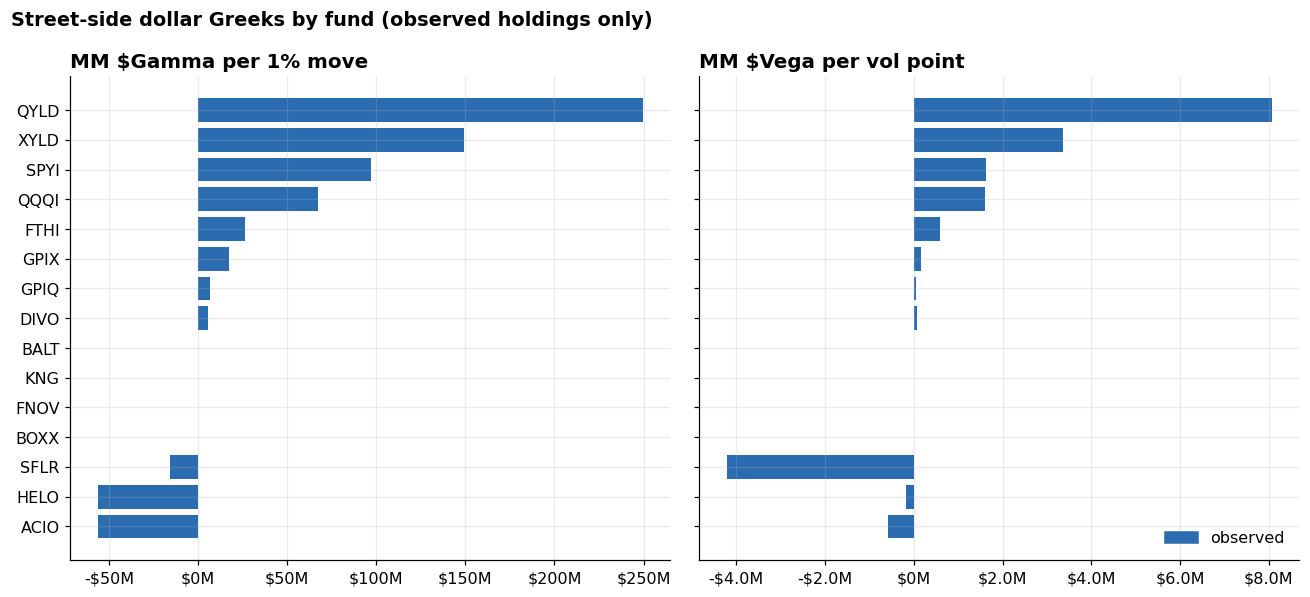

In [22]:
priced = greek_engine.add_expiry_bucket(greek_engine.price_book(book, mkt))
by_fund = greek_engine.aggregate(priced, by="fund").join(
    etfs.set_index("fund")[["aum_usd", "bucket"]]
)
by_fund["source"] = coverage.set_index("fund")["status"]
by_fund["gamma_pct_aum"] = by_fund["mm_dollar_gamma_1pct"] / by_fund["aum_usd"]
by_fund = by_fund.sort_values("mm_dollar_gamma_1pct")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
colors = by_fund["source"].map(ps.COLORS)
labels = by_fund.index.str.replace(" US Equity", "", regex=False)

axes[0].barh(labels, by_fund["mm_dollar_gamma_1pct"], color=colors)
axes[0].set_title("MM $Gamma per 1% move")
ps.usd(axes[0], "x")

axes[1].barh(labels, by_fund["mm_dollar_vega_1vol"], color=colors)
axes[1].set_title("MM $Vega per vol point")
ps.usd(axes[1], "x")
axes[1].legend(
    handles=[Patch(color=ps.COLORS["observed"], label="observed")],
    loc="lower right",
)
fig.suptitle("Street-side dollar Greeks by fund (observed holdings only)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()


In [23]:
tot = greek_engine.aggregate(priced).iloc[0]
print(
    f"TOTAL (observed funds): street $Gamma per 1% = {ps.money(tot.mm_dollar_gamma_1pct)}, "
    f"$Vega per vol pt = {ps.money(tot.mm_dollar_vega_1vol)}, "
    f"across {len(priced)} legs / {priced.fund.nunique()} funds"
)
by_fund[[
    "bucket", "source", "aum_usd",
    "mm_dollar_gamma_1pct", "mm_dollar_vega_1vol", "gamma_pct_aum",
]].sort_values("mm_dollar_gamma_1pct", ascending=False)


TOTAL (observed funds): street $Gamma per 1% = $489.8M, $Vega per vol pt = $10.5M, across 285 legs / 15 funds


,bucket,source,aum_usd,mm_dollar_gamma_1pct,mm_dollar_vega_1vol,gamma_pct_aum
fund,,,,,,
QYLD US Equity,Index covered call,observed,"7,740,906,000","249,675,962","8,072,126",0.0323
XYLD US Equity,Index covered call,observed,"3,187,283,000","149,306,665","3,367,491",0.0468
SPYI US Equity,Index option income,observed,"12,195,136,000","96,729,507","1,615,885",0.0079
QQQI US Equity,Index option income,observed,"14,467,057,000","67,274,790","1,602,174",0.0047
FTHI US Equity,Buy-write income,observed,"2,420,448,000","26,126,818","579,325",0.0108
GPIX US Equity,Active option income,observed,"6,386,987,000","17,303,350","160,587",0.0027
GPIQ US Equity,Active option income,observed,"6,215,317,000","6,346,546","57,944",0.0010
DIVO US Equity,Tactical single-stock covered call,observed,"7,606,742,000","5,505,072","73,954",0.0007
BALT US Equity,Shield/defined outcome,observed,"3,288,899,000","47,601","1,069",0.0000


## 3 · Where does it sit? By underlying and by expiry
Short-dated legs carry most of the gamma; longer-dated legs carry the vega.

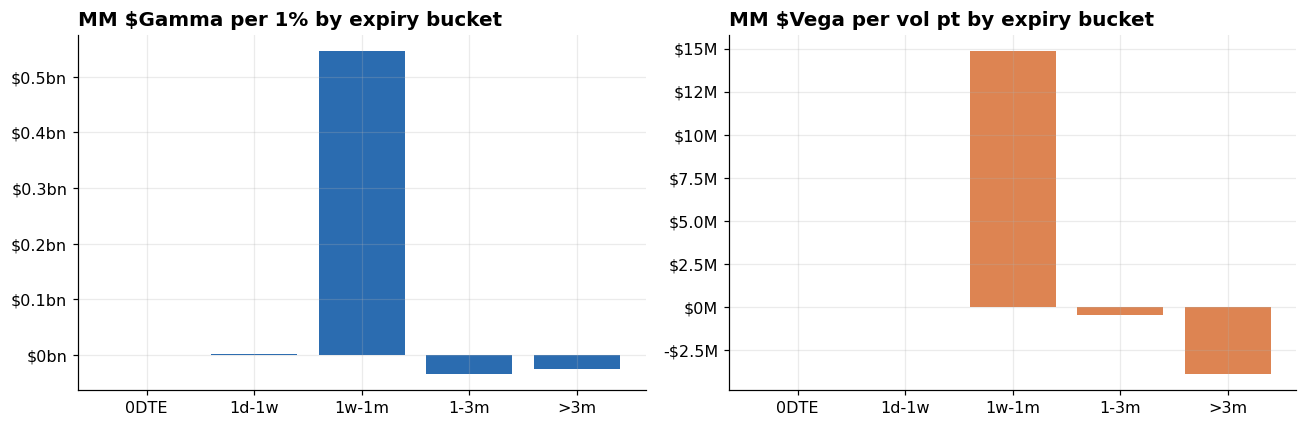

,mm_dollar_delta,mm_dollar_gamma_1pct,mm_dollar_vega_1vol,n_legs
underlying,,,,
NDX,"3,426,293,439","316,950,752","9,674,301",4
SPX,"2,582,493,422","210,458,552","4,468,058",28
SPY,"-210,817,281,325","-73,206,431","-4,376,515",33
DUK,"24,494,044","6,408,135","91,045",4
QQQ,"10,843,840","6,346,546","57,944",8
AAPL,"30,280,181","6,013,384","117,752",4
BRK/B,"21,907,996","2,440,340","39,861",1
COST,"9,038,194","957,225","19,366",3
WMT,"17,479,580","807,520","30,378",5


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_expiry = greek_engine.aggregate(priced, by="expiry_bucket")
axes[0].bar(by_expiry.index.astype(str), by_expiry["mm_dollar_gamma_1pct"], color=ps.COLORS["accent"])
ps.usd(axes[0], "y", 1e9, "bn")
axes[0].set_title("MM $Gamma per 1% by expiry bucket")

axes[1].bar(by_expiry.index.astype(str), by_expiry["mm_dollar_vega_1vol"], color=ps.COLORS["inferred"])
ps.usd(axes[1])
axes[1].set_title("MM $Vega per vol pt by expiry bucket")
plt.tight_layout()
plt.show()

greek_engine.aggregate(priced, by="underlying")[[
    "mm_dollar_delta", "mm_dollar_gamma_1pct", "mm_dollar_vega_1vol", "n_legs"
]].sort_values("mm_dollar_gamma_1pct", key=abs, ascending=False).head(15)


## 4 · Spot ladder by strategy bucket
Street gamma as the index moves — the core “impact on the vol environment” chart.

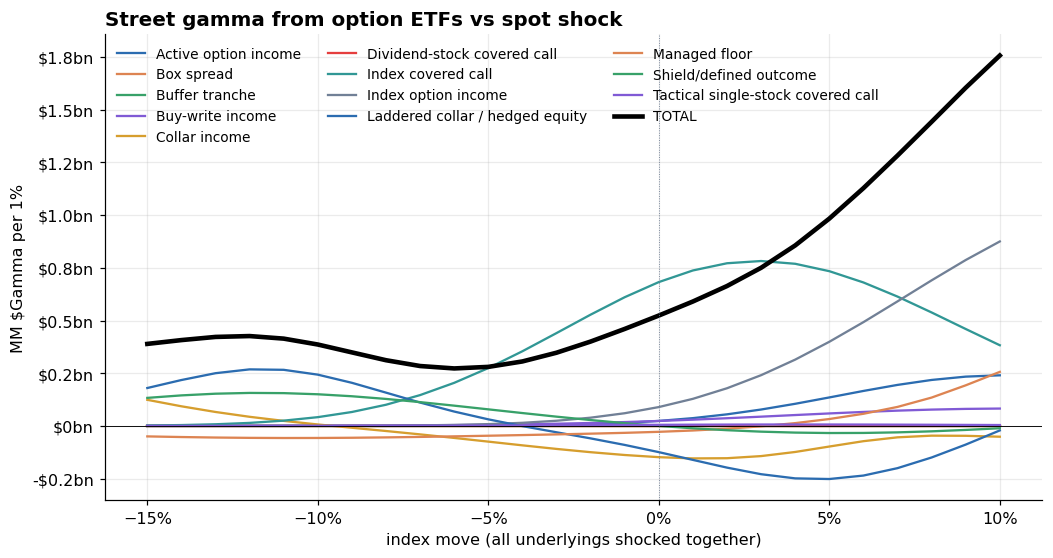

gamma flip shock: None


In [25]:
shocks = np.round(np.linspace(-0.15, 0.10, 26), 3)
ladder = greek_engine.spot_ladder(book, mkt, shocks, by="bucket")
pivot = ladder.pivot_table(
    index="shock", columns="bucket", values="mm_dollar_gamma_1pct", aggfunc="sum"
)
total = pivot.sum(axis=1)
flip = greek_engine.gamma_flip(ladder)

fig, ax = plt.subplots(figsize=(11, 5.5))
for i, bucket in enumerate(pivot.columns):
    ax.plot(pivot.index, pivot[bucket], lw=1.5, color=ps.BUCKET_COLORS[i % 8], label=bucket)
ax.plot(total.index, total, lw=3, color="black", label="TOTAL")
ax.axhline(0, color="black", lw=0.6)
ax.axvline(0, color=ps.COLORS["grey"], lw=0.6, ls=":")
if flip is not None:
    ax.axvline(flip, color=ps.COLORS["neg"], lw=1.2)
    ax.annotate(
        f"total gamma flips\nat {flip:+.1%}",
        (flip, 0),
        xytext=(-0.145, float(total.max()) * 0.35),
        textcoords="data",
        arrowprops=dict(arrowstyle="->", color=ps.COLORS["neg"]),
        color=ps.COLORS["neg"],
    )
ps.pct(ax, "x")
ps.usd(ax, "y", 1e9, "bn")
ax.set_xlabel("index move (all underlyings shocked together)")
ax.set_ylabel("MM $Gamma per 1%")
ax.set_title("Street gamma from option ETFs vs spot shock")
ax.legend(ncol=3, fontsize=9)
plt.show()
print("gamma flip shock:", None if flip is None else f"{flip:+.2%}")


## 5 · Translate gamma into hedge flow
If dealers hedge fully, the trade after a move is the change in their dollar delta.
**Positive** ⇒ they **buy** (long-gamma dealers support the market on a dip).

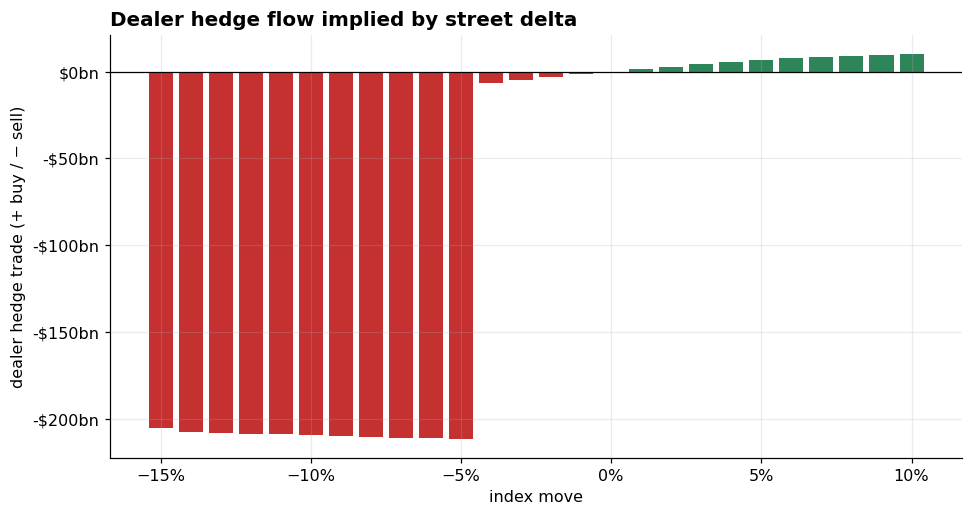

Near -1%: dealers sell $1.5bn (shock used -1.0%)
Near -5%: dealers sell $211.4bn (shock used -5.0%)


In [26]:
ladder_total = greek_engine.spot_ladder(book, mkt, shocks).set_index("shock")
flow = -(ladder_total["mm_dollar_delta"] - ladder_total["mm_dollar_delta"].loc[0.0])

fig, ax = plt.subplots()
ax.bar(
    flow.index, flow, width=0.008,
    color=np.where(flow.to_numpy() >= 0, ps.COLORS["pos"], ps.COLORS["neg"]),
)
ax.axhline(0, color="black", lw=0.8)
ps.pct(ax, "x")
ps.usd(ax, "y", 1e9, "bn")
ax.set_xlabel("index move")
ax.set_ylabel("dealer hedge trade (+ buy / − sell)")
ax.set_title("Dealer hedge flow implied by street delta")
plt.show()

def nearest_flow(shock):
    idx = flow.index.to_numpy()
    j = int(np.argmin(np.abs(idx - shock)))
    return float(idx[j]), float(flow.iloc[j])

for shock in (-0.01, -0.05):
    used, value = nearest_flow(shock)
    side = "buy" if value >= 0 else "sell"
    print(f"Near {shock:+.0%}: dealers {side} {ps.money(abs(value))} (shock used {used:+.1%})")


## 6 · Next: prospectus inference
Skipped funds (JEPI, JEPQ, BUFR, BUFD, ACYN, …) will get synthetic books from prospectus rules later.
This notebook prices **observed holdings only**.


In [27]:
skipped = coverage.loc[coverage["status"] == "skipped", ["fund", "bucket", "aum_usd", "note"]]
skipped.sort_values("aum_usd", ascending=False)


,fund,bucket,aum_usd,note


## Data

All inputs come from `data/sheets/`:
- `ETF_List.csv`
- `Option_Book_Copy.csv`
- `Underlying_Market_Copy.csv`
- `holdings/<TICKER>.csv`

Do not point code at `data/Project10_ETF_List.xlsx`.
